# Day 2:  <font color = "red">**Structure → Property Challenge**</font>

Can local image structure predict the local EELS response?

For each location, we have:

**Image patch → EELS spectrum → Scalarizer**

Your task is to:

1. Build a <font color = "purple">**descriptor**</font> for the image patch.
2. Use a <font color = "purple">**regressor**</font> to predict a scalarizer or the full spectrum.
3. Compare methods by:
   - predictive power
   - complexity
   - explainability

<font color = "green">**Goal**</font>

> Find the simplest explainable descriptor that predicts the EELS response well.

## <font color = "purple">**1.**</font> Explore the Dataset

Each spatial location contains:

- one image intensity value
- one full EELS spectrum

The same position in the image corresponds to the same position in the EELS spectrum image.

Let's look at one dataset.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kbarakati/athena_camm_hackathon/blob/k4my4r/docs/day_17_18092026/notebook.ipynb)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression
import os

In [ ]:
!gdown --fuzzy 1FKmlRTRDImQS91V4YQjcQHoJU19X6P_6

Downloading...
From (original): https://drive.google.com/uc?id=1FKmlRTRDImQS91V4YQjcQHoJU19X6P_6
From (redirected): https://drive.google.com/uc?id=1FKmlRTRDImQS91V4YQjcQHoJU19X6P_6&confirm=t&uuid=ddbb0707-d009-4da7-a17c-56395ad9f046
To: /content/Plasmonic_sets_hackathon.npy
100% 584M/584M [00:02<00:00, 226MB/s]  


In [ ]:
file_name = "/content/Plasmonic_sets_hackathon.npy"

raw = np.load(
    file_name,
    allow_pickle=True
)

loadedfile = raw.tolist()
print("keys:", loadedfile.keys())

keys: dict_keys(['0', '1', '2', '3'])


In [ ]:
# Choose dataset
data = loadedfile["2"]

image = data["image"]
spectra = data["spectrum image"]
energy = data["energy axis"]

H, W = image.shape

print(image.shape)
print(spectra.shape)
print(energy.shape)

(33, 63)
(33, 63, 4322)
(4322,)


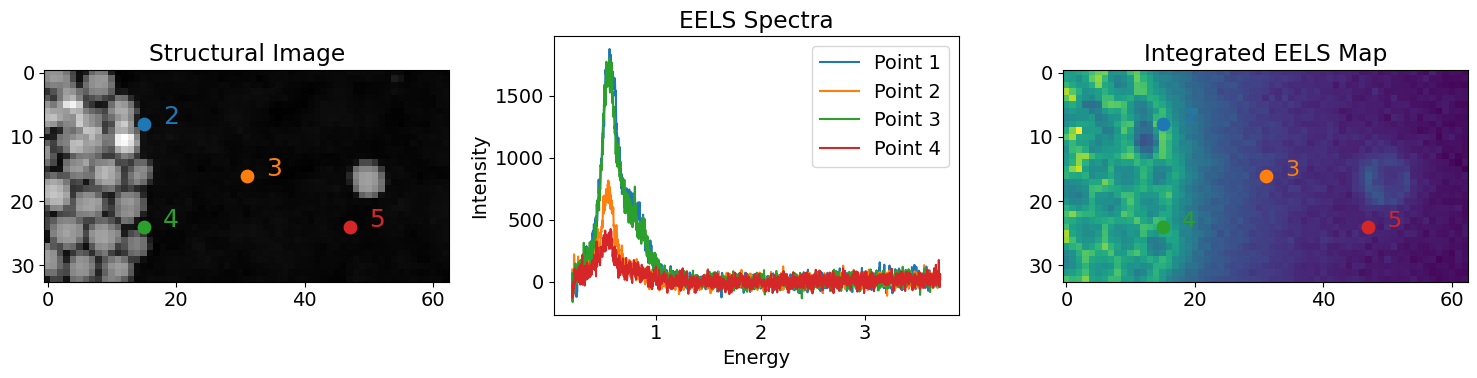

In [ ]:
# Example locations
positions = [
    (H // 4, W // 4),
    (H // 2, W // 2),
    (3 * H // 4, W // 4),
    (3 * H // 4, 3 * W // 4),
]

colors = ["C0", "C1", "C2", "C3"]

# Integrated EELS map
eels_map = spectra.sum(axis=2)

plt.rcParams.update({"font.size": 14})

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Structural image
ax[0].imshow(image, cmap="gray")
ax[0].set_title("Structural Image")

# Spectra
for i, ((y, x), color) in enumerate(zip(positions, colors)):

    ax[0].scatter(x, y, s=80, color=color)
    ax[0].text(x + 3, y, str(i + 2), color=color, fontsize=18)

    ax[1].plot(
        energy,
        spectra[y, x],
        color=color,
        label=f"Point {i + 1}"
    )

    ax[2].scatter(x, y, s=80, color=color)
    ax[2].text(x + 3, y, str(i + 2), color=color, fontsize=16)

ax[1].set_title("EELS Spectra")
ax[1].set_xlabel("Energy")
ax[1].set_ylabel("Intensity")
ax[1].legend()

# EELS map
ax[2].imshow(eels_map)
ax[2].set_title("Integrated EELS Map")

plt.tight_layout()
plt.show()

## <font color = "purple">**2.**</font> Define a Scalarizer

Each EELS spectrum can be reduced to a **single target value** called a scalarizer.

For example, the spectral intensity within an energy window:

$$
S(x,y)=\int_{E_1}^{E_2} I(x,y,E)\,dE
$$

where \(E_1\) and \(E_2\) define the spectral region of interest.

Other possible scalarizers include:

- peak intensity
- peak position
- peak area
- peak ratio

## <font color = "purple">**3.**</font> Choose a Spectral Region

Before defining the scalarizer, inspect the EELS spectrum and choose an energy range containing a feature of interest.

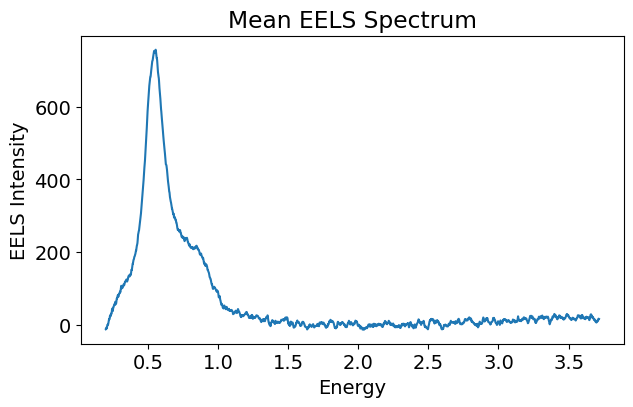

In [ ]:
# Mean spectrum over the whole image
mean_spectrum = spectra.mean(axis=(0, 1))

plt.figure(figsize=(7, 4))

plt.plot(energy, mean_spectrum)

plt.xlabel("Energy")
plt.ylabel("EELS Intensity")
plt.title("Mean EELS Spectrum")

plt.show()

## <font color = "purple">**4.**</font> Calculate the Scalarizer

We integrate the EELS intensity inside the selected energy window to obtain one target value at each spatial location.

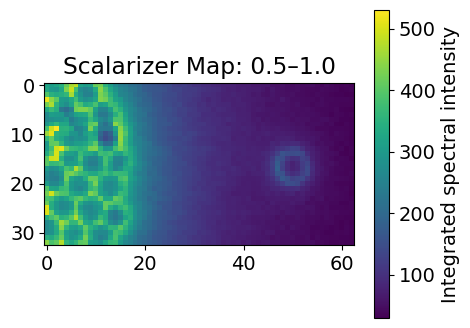

In [ ]:
# Choose an energy range
E1 = 0.5
E2 = 1.0

mask = (energy >= E1) & (energy <= E2)

scalarizer_map = np.trapezoid(
    spectra[:, :, mask],
    energy[mask],
    axis=2
)

plt.figure(figsize=(5, 4))
plt.imshow(scalarizer_map)
plt.colorbar(label="Integrated spectral intensity")
plt.title(f"Scalarizer Map: {E1}–{E2}")
plt.show()

## <font color = "purple">**5.**</font> Create Patch–Spectrum–Scalarizer Pairs

For each location we collect:

**Image patch → EELS spectrum → Scalarizer**

The spectrum and scalarizer correspond to the center pixel of the patch.

In [ ]:
PATCH_SIZE = 5
half = PATCH_SIZE // 2

patches = []
targets = []

for y in range(half, H - half):
    for x in range(half, W - half):

        patch = image[y-half:y+half+1, x-half:x+half+1]

        patches.append(patch)
        targets.append(scalarizer_map[y, x])

patches = np.array(patches)
targets = np.array(targets)

print("Patches:", patches.shape)
print("Targets:", targets.shape)

Patches: (1711, 5, 5)
Targets: (1711,)


## <font color = "purple">**6.**</font> Look at Example Pairs

Each patch has one target scalarizer value.

Can you see structural differences between low and high target values?

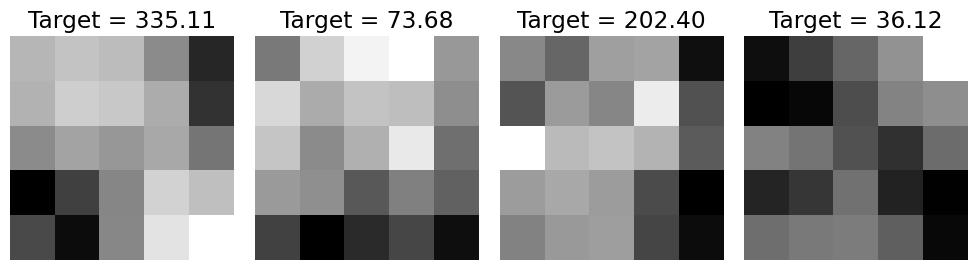

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(10, 3))

ids = np.linspace(0, len(patches) - 1, 4, dtype=int)

for i, idx in enumerate(ids):
    ax[i].imshow(patches[idx], cmap="gray")
    ax[i].set_title(f"Target = {targets[idx]:.2f}")
    ax[i].axis("off")

plt.tight_layout()
plt.show()

## The Challenge

You will design two parts of the prediction pipeline:

**Image Patch → Descriptor → Regressor → EELS Scalarizer**

### Your goal

Find a combination with:

- high predictive power
- low complexity
- good explainability

You can change:

1. the **descriptor** — how the image patch is represented
2. the **regressor** — how the descriptor is mapped to the EELS property

Try different combinations and compare their performance.

## <font color = "purple">**7.**</font> Define Your Descriptor and Regressor

Change only the code inside the marked sections.

The descriptor converts an image patch into features.

The regressor learns how those features relate to the EELS scalarizer.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge


def descriptor(patch):

    # ============================================================
    # YOUR CODE STARTS HERE
    # ============================================================

    p = patch.astype(float)

    # --- local gradient field (edge strength inside the patch) ---
    gy, gx = np.gradient(p)
    grad = np.hypot(gx, gy)

    mean = p.mean()
    center = p[half, half]

    features = [
        mean,                 # 1. thickness / mass-density proxy (ADF ~ t*Z)
        p.std(),              # 2. local contrast: is this a flat region or a boundary?
        center,               # 3. the pixel the EELS spectrum actually belongs to
        center - mean,        # 4. local relief: is the centre a peak, a dip, or flat?
        grad.mean(),          # 5. average edge strength -> surface-plasmon hot spots
        grad.max(),           # 6. strongest single edge in the patch
    ]

    # ============================================================
    # YOUR CODE ENDS HERE
    # ============================================================

    return features


def regressor():

    # ============================================================
    # YOUR CODE STARTS HERE
    # ============================================================

    model = RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=5,     # smooths the fit, limits memorisation
        n_jobs=-1,
        random_state=0,
    )

    # Interpretable alternative (swap in to see the accuracy/explainability trade):
    # model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))

    # ============================================================
    # YOUR CODE ENDS HERE
    # ============================================================

    return model


## <font color = "purple">**8.**</font> Run Your Pipeline

Now we test your descriptor–regressor combination.

The same train/test split is used each time so different combinations can be compared fairly.

In [ ]:
# Build descriptor matrix
X = np.array([descriptor(patch) for patch in patches])

# Same split for every experiment
X_train, X_test, y_train, y_test = train_test_split(
    X,
    targets,
    test_size=0.25,
    random_state=0
)

# Train
model = regressor()
model.fit(X_train, y_train)

# Predict
predictions = model.predict(X_test)

# Evaluate
r2 = r2_score(y_test, predictions)

print("Regressor:", type(model).__name__)
print("Number of features:", X.shape[1])
print(f"R²: {r2:.3f}")

Regressor: RandomForestRegressor
Number of features: 6
R²: 0.787


## <font color = "purple">**9.**</font> Compare Prediction with Ground Truth

A good model should predict values close to the measured EELS scalarizer.

Points closer to the diagonal line indicate better agreement.

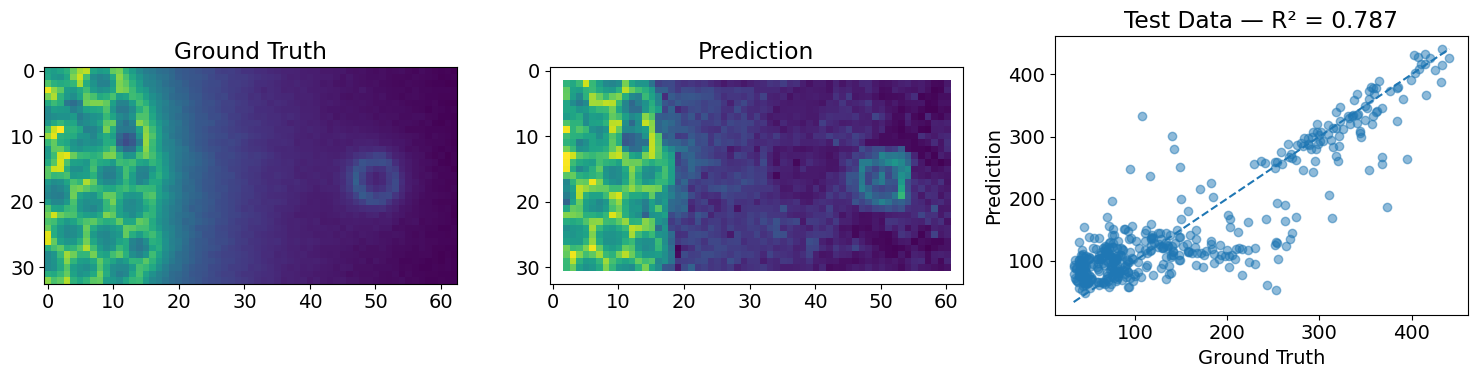

In [ ]:
# Size of valid prediction region
map_shape = (
    H - 2 * half,
    W - 2 * half
)

# Predicted values
predicted = model.predict(X).reshape(map_shape)

# Put predictions back into an image of the original size
prediction_map = np.full((H, W), np.nan)

prediction_map[
    half:H-half,
    half:W-half
] = predicted


fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].imshow(scalarizer_map)
ax[0].set_title("Ground Truth")

ax[1].imshow(prediction_map)
ax[1].set_title("Prediction")

# Test data
ax[2].scatter(y_test, predictions, alpha=0.5)

low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())

ax[2].plot([low, high], [low, high], "--")
ax[2].set_xlabel("Ground Truth")
ax[2].set_ylabel("Prediction")
ax[2].set_title(f"Test Data — R² = {r2:.3f}")

plt.tight_layout()
plt.show()

## <font color = "purple">**10.**</font> Compare Descriptor–Regressor Combinations

Test several descriptors and regressors.

Create a heatmap where:

- rows = descriptors
- columns = regressors
- color/value = test R²

Use the same train/test split for every combination.

### <font color = "red">**Goal**</font>

Identify which descriptor–regressor combinations give the strongest predictive performance.

descriptors: {'center (1)': 1, 'stats3 (3)': 3, 'stats+grad (6)': 6, 'gradient (5)': 5, 'fft (3)': 3, 'raw 5x5 (25)': 25, 'position (2)': 2, 'multiscale (10)': 10, 'proximity (4)': 4, 'proximity+stats (7)': 7, 'geometry (4)': 4}
BLOCK=8px  random 1284/427   spatial 1043/172

=== random (leaky) ===
  center (1)           Ridge=0.32  Lasso=0.32  Poly2+Ridge=0.49  kNN(15)=0.61  Tree(d=4)=0.60  RandomForest=0.60  HistGBM=0.62
  stats3 (3)           Ridge=0.63  Lasso=0.63  Poly2+Ridge=0.68  kNN(15)=0.72  Tree(d=4)=0.66  RandomForest=0.73  HistGBM=0.74
  stats+grad (6)       Ridge=0.71  Lasso=0.71  Poly2+Ridge=0.73  kNN(15)=0.74  Tree(d=4)=0.73  RandomForest=0.77  HistGBM=0.77
  gradient (5)         Ridge=0.69  Lasso=0.69  Poly2+Ridge=0.71  kNN(15)=0.71  Tree(d=4)=0.65  RandomForest=0.71  HistGBM=0.70
  fft (3)              Ridge=0.50  Lasso=0.50  Poly2+Ridge=0.56  kNN(15)=0.62  Tree(d=4)=0.61  RandomForest=0.64  HistGBM=0.61
  raw 5x5 (25)         Ridge=0.71  Lasso=0.71  Poly2+Ridge=0.74  k

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.191e+05, tolerance: 1.674e+03
  model = cd_fast.enet_coordinate_descent(


  stats+grad (6)       Ridge=-0.05  Lasso=-0.05  Poly2+Ridge=-0.11  kNN(15)=-0.63  Tree(d=4)=-0.88  RandomForest=-0.83  HistGBM=-1.33
  gradient (5)         Ridge=-0.07  Lasso=-0.07  Poly2+Ridge=-0.22  kNN(15)=-0.25  Tree(d=4)=-1.12  RandomForest=-0.78  HistGBM=-0.93
  fft (3)              Ridge=-0.13  Lasso=-0.13  Poly2+Ridge=-0.02  kNN(15)=-0.63  Tree(d=4)=-1.02  RandomForest=-0.86  HistGBM=-0.71
  raw 5x5 (25)         Ridge=0.04  Lasso=0.04  Poly2+Ridge=0.04  kNN(15)=-0.40  Tree(d=4)=-0.31  RandomForest=-0.16  HistGBM=-0.40
  position (2)         Ridge=-0.25  Lasso=-0.25  Poly2+Ridge=0.59  kNN(15)=-0.64  Tree(d=4)=0.90  RandomForest=0.74  HistGBM=0.72
  multiscale (10)      Ridge=0.80  Lasso=0.81  Poly2+Ridge=0.82  kNN(15)=0.91  Tree(d=4)=0.60  RandomForest=0.91  HistGBM=0.88
  proximity (4)        Ridge=0.81  Lasso=0.80  Poly2+Ridge=0.97  kNN(15)=0.96  Tree(d=4)=0.92  RandomForest=0.98  HistGBM=0.98
  proximity+stats (7)  Ridge=0.95  Lasso=0.95  Poly2+Ridge=0.96  kNN(15)=0.94  Tree

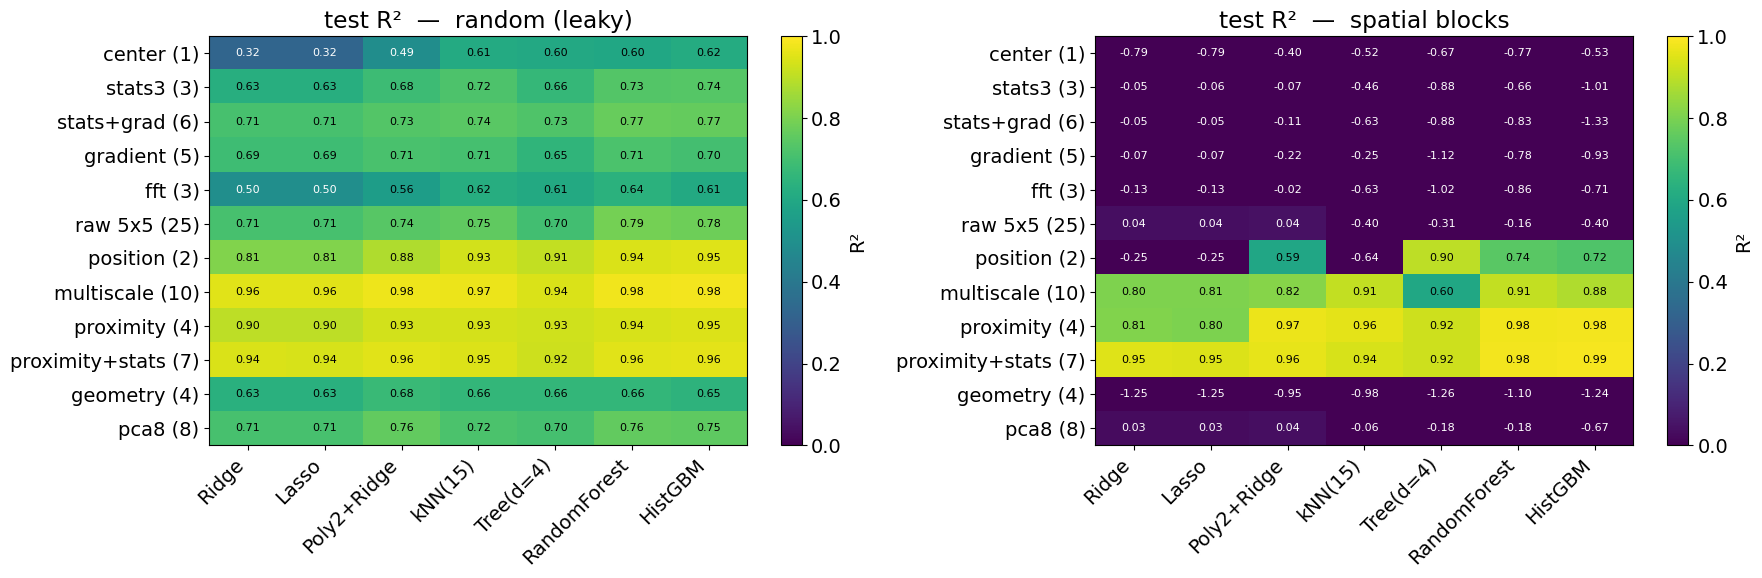

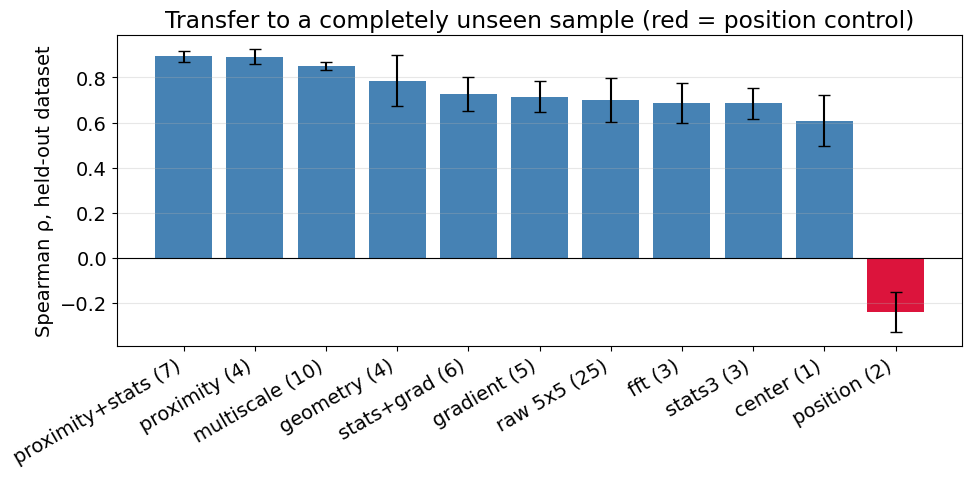

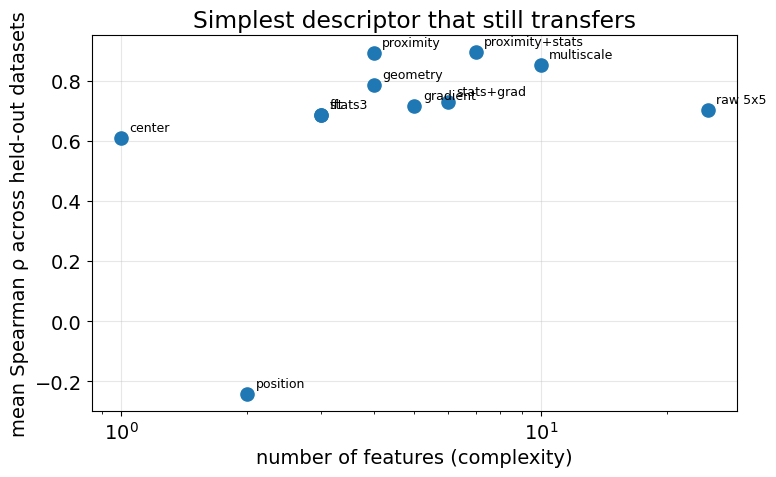

In [ ]:
# ============================================================
# YOUR CODE STARTS HERE
# ============================================================
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import (uniform_filter, gaussian_filter, minimum_filter,
                           maximum_filter, distance_transform_edt)
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score

# ------------------------------------------------------------------
# 1. DESCRIPTOR LIBRARY
# ------------------------------------------------------------------
def _otsu(a, nbins=64):
    h, e = np.histogram(a, bins=nbins); c = 0.5 * (e[:-1] + e[1:])
    w0 = np.cumsum(h); w1 = w0[-1] - w0
    cs = np.cumsum(h * c)
    m0 = cs / np.maximum(w0, 1); m1 = (cs[-1] - cs) / np.maximum(w1, 1)
    return c[np.argmax(w0 * w1 * (m0 - m1) ** 2)]

def d_center(p):    return [p[half, half]]
def d_stats3(p):    return [p.mean(), p.std(), p.max() - p.min()]
def d_stats_grad(p):
    p = p.astype(float); gy, gx = np.gradient(p); g = np.hypot(gx, gy)
    m, c = p.mean(), p[half, half]
    return [m, p.std(), c, c - m, g.mean(), g.max()]
def d_gradient(p):
    p = p.astype(float); gy, gx = np.gradient(p); g = np.hypot(gx, gy)
    lap = (p[:-2,1:-1]+p[2:,1:-1]+p[1:-1,:-2]+p[1:-1,2:]-4*p[1:-1,1:-1]).mean()
    Jxx, Jyy, Jxy = (gx*gx).mean(), (gy*gy).mean(), (gx*gy).mean()
    coh = np.sqrt((Jxx-Jyy)**2 + 4*Jxy**2) / (Jxx+Jyy+1e-12)
    return [g.mean(), g.max(), g.std(), lap, coh]
_rr = np.hypot(*(np.indices((PATCH_SIZE, PATCH_SIZE)) - half))
def d_fft(p):
    F = np.abs(np.fft.fftshift(np.fft.fft2(p.astype(float) - p.mean())))**2
    return [np.log1p(F[_rr<1.5].sum()), np.log1p(F[(_rr>=1.5)&(_rr<2.5)].sum()), np.log1p(F[_rr>=2.5].sum())]
def d_raw(p):       return p.astype(float).ravel().tolist()

PATCH_DESCRIPTORS = {"center (1)": d_center, "stats3 (3)": d_stats3,
                     "stats+grad (6)": d_stats_grad, "gradient (5)": d_gradient,
                     "fft (3)": d_fft, "raw 5x5 (25)": d_raw}

PROX_NM = (5, 15, 30, 60)   # kernel widths in NANOMETRES, so datasets are comparable

def build_features(img, scale_nm, ys, xs):
    """All descriptors for one dataset, evaluated at the patch centres (ys, xs)."""
    im = img.astype(float)
    out = {}
    for name, fn in PATCH_DESCRIPTORS.items():
        out[name] = np.array([fn(im[y-half:y+half+1, x-half:x+half+1]) for y, x in zip(ys, xs)], float)

    # CONTROL: position only. Contains zero structural information.
    out["position (2)"] = np.column_stack([ys, xs]).astype(float)

    # multiscale intensity statistics
    cols = []
    for s in (3, 5, 11, 21, 41):
        a = uniform_filter(im, size=s, mode="reflect"); b = uniform_filter(im**2, size=s, mode="reflect")
        cols += [a[ys, xs], np.sqrt(np.clip(b - a**2, 0, None))[ys, xs]]
    out["multiscale (10)"] = np.column_stack(cols)

    # PROXIMITY: how much material lies within r nm of me
    sm = gaussian_filter(im, 1.0)
    mask = (sm > _otsu(sm)).astype(float)
    out["proximity (4)"] = np.column_stack([gaussian_filter(mask, r/scale_nm)[ys, xs] for r in PROX_NM])
    out["proximity+stats (7)"] = np.column_stack([out["proximity (4)"], out["stats3 (3)"]])

    # explicit boundary geometry
    d_in, d_out = distance_transform_edt(mask > .5), distance_transform_edt(mask <= .5)
    signed = (d_in - d_out) * scale_nm
    gy, gx = np.gradient(sm)
    out["geometry (4)"] = np.column_stack([signed[ys,xs], np.abs(signed)[ys,xs],
                                           np.hypot(gx,gy)[ys,xs], mask[ys,xs]])
    return out

def patch_grid(Hh, Ww):
    a, b = np.meshgrid(np.arange(half, Hh-half), np.arange(half, Ww-half), indexing="ij")
    return a.ravel(), b.ravel()

ys, xs = patch_grid(H, W)
X_ALL = build_features(image, float(data["scale"]), ys, xs)
PCA_FROM_RAW = {"pca8 (8)": 8}
print("descriptors:", {k: v.shape[1] for k, v in X_ALL.items()})

# ------------------------------------------------------------------
# 2. REGRESSORS
# ------------------------------------------------------------------
REGRESSORS = {
 "Ridge":        lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
 "Lasso":        lambda: make_pipeline(StandardScaler(), Lasso(alpha=1e-3, max_iter=5000)),
 "Poly2+Ridge":  lambda: make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), Ridge(alpha=10.0)),
 "kNN(15)":      lambda: make_pipeline(StandardScaler(), KNeighborsRegressor(15)),
 "Tree(d=4)":    lambda: DecisionTreeRegressor(max_depth=4, random_state=0),
 "RandomForest": lambda: RandomForestRegressor(n_estimators=150, min_samples_leaf=5, n_jobs=-1, random_state=0),
 "HistGBM":      lambda: HistGradientBoostingRegressor(random_state=0),
}

# ------------------------------------------------------------------
# 3. SPLITS INSIDE THIS DATASET
# ------------------------------------------------------------------
BLOCK = max(6, min(H, W) // 4)
rng = np.random.default_rng(0)
bt = rng.random((H//BLOCK + 1, W//BLOCK + 1)) < 0.25
yy, xx = np.indices((H, W)); t = bt[yy//BLOCK, xx//BLOCK].astype(float)
spatial_test  = minimum_filter(t, size=PATCH_SIZE, mode="nearest")[ys, xs] > .5
spatial_train = maximum_filter(t, size=PATCH_SIZE, mode="nearest")[ys, xs] < .5
perm = np.random.default_rng(0).permutation(len(ys)); nt = int(.25*len(ys))
rand_test = np.zeros(len(ys), bool); rand_test[perm[:nt]] = True
rand_train = ~rand_test
SPLITS = {"random (leaky)": (rand_train, rand_test), "spatial blocks": (spatial_train, spatial_test)}
print(f"BLOCK={BLOCK}px  random {rand_train.sum()}/{rand_test.sum()}   "
      f"spatial {spatial_train.sum()}/{spatial_test.sum()}")

desc_names = list(X_ALL) + list(PCA_FROM_RAW); reg_names = list(REGRESSORS)
scores = {s: np.full((len(desc_names), len(reg_names)), np.nan) for s in SPLITS}
n_features = {}
t0 = time.time()
for sname, (tr, te) in SPLITS.items():
    print(f"\n=== {sname} ===")
    for i, dn in enumerate(desc_names):
        if dn in PCA_FROM_RAW:
            base = X_ALL["raw 5x5 (25)"]
            X = PCA(n_components=PCA_FROM_RAW[dn], random_state=0).fit(base[tr]).transform(base)
        else:
            X = X_ALL[dn]
        n_features[dn] = X.shape[1]
        line = []
        for j, rn in enumerate(reg_names):
            mdl = REGRESSORS[rn]().fit(X[tr], targets[tr])
            scores[sname][i, j] = r2_score(targets[te], mdl.predict(X[te]))
            line.append(f"{rn}={scores[sname][i,j]:.2f}")
        print(f"  {dn:<20} " + "  ".join(line))

# ------------------------------------------------------------------
# 4. LEAVE-ONE-DATASET-OUT  (the only test with no spatial leakage at all)
# ------------------------------------------------------------------
print("\nbuilding features for every dataset ...")
DS = {}
for k in loadedfile:
    dk = loadedfile[k]; imk = np.asarray(dk["image"]); spk = np.asarray(dk["spectrum image"])
    enk = np.asarray(dk["energy axis"]); sck = float(dk["scale"])
    mk = (enk >= E1) & (enk <= E2)
    tgt_map = np.trapezoid(spk[:, :, mk], enk[mk], axis=2)
    yk, xk = patch_grid(*imk.shape)
    DS[k] = dict(F=build_features(imk, sck, yk, xk), y=tgt_map[yk, xk],
                 ys=yk, xs=xk, shape=imk.shape, scale=sck)
    print(f"  ds{k}: {imk.shape} {sck:.1f} nm/px  n={len(yk)}")

def zs(a):
    a = np.asarray(a, float); s = np.atleast_1d(a.std(axis=0)); s[s == 0] = 1
    return (a - a.mean(axis=0)) / s

lodo_names = [d for d in X_ALL]               # PCA skipped here
LODO_CAP = 6000                               # subsample training rows to keep this quick
_rng = np.random.default_rng(0)
lodo_r2 = np.zeros((len(lodo_names), len(DS)))
lodo_rho = np.zeros_like(lodo_r2)
for j, hold in enumerate(DS):
    tr_k = [k for k in DS if k != hold]
    for i, dn in enumerate(lodo_names):
        Xtr = np.vstack([zs(DS[k]["F"][dn]) for k in tr_k])
        ytr = np.concatenate([zs(DS[k]["y"]) for k in tr_k])
        sub = _rng.permutation(len(ytr))[:LODO_CAP]
        Xte, yte = zs(DS[hold]["F"][dn]), zs(DS[hold]["y"])
        pr = RandomForestRegressor(150, min_samples_leaf=5, n_jobs=-1,
                                   random_state=0).fit(Xtr[sub], ytr[sub]).predict(Xte)
        lodo_r2[i, j] = r2_score(yte, pr)
        lodo_rho[i, j] = spearmanr(yte, pr).statistic

print(f"\n--- leave-one-dataset-out (RandomForest, z-scored per dataset) ---")
print(f"{'descriptor':<22}" + "".join(f"  hold ds{k}" for k in DS) + "     mean rho")
for i, dn in enumerate(lodo_names):
    print(f"{dn:<22}" + "".join(f"  {lodo_rho[i,j]:8.2f}" for j in range(len(DS)))
          + f"  {lodo_rho[i].mean():10.2f}")
print(f"\ntotal time {time.time()-t0:.0f}s")

# ------------------------------------------------------------------
# 5. FIGURES
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, (sn, M) in zip(axes, scores.items()):
    h = ax.imshow(M, cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(reg_names))); ax.set_xticklabels(reg_names, rotation=45, ha="right")
    ax.set_yticks(range(len(desc_names))); ax.set_yticklabels(desc_names)
    ax.set_title(f"test R²  —  {sn}")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i,j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if M[i,j] < .55 else "black")
    fig.colorbar(h, ax=ax, label="R²")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
o = np.argsort(-lodo_rho.mean(axis=1))
ax.bar(range(len(o)), lodo_rho.mean(axis=1)[o],
       yerr=lodo_rho.std(axis=1)[o], capsize=4,
       color=["crimson" if lodo_names[k] == "position (2)" else "steelblue" for k in o])
ax.set_xticks(range(len(o))); ax.set_xticklabels([lodo_names[k] for k in o], rotation=30, ha="right")
ax.set_ylabel("Spearman ρ, held-out dataset"); ax.axhline(0, color="k", lw=.8)
ax.set_title("Transfer to a completely unseen sample (red = position control)")
ax.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

nf = np.array([n_features.get(d, X_ALL[d].shape[1]) for d in lodo_names])
plt.figure(figsize=(8, 5))
plt.scatter(nf, lodo_rho.mean(axis=1), s=90, zorder=3)
for k, d in enumerate(lodo_names):
    plt.annotate(d.split(" (")[0], (nf[k], lodo_rho[k].mean()),
                 textcoords="offset points", xytext=(6, 5), fontsize=9)
plt.xscale("log"); plt.xlabel("number of features (complexity)")
plt.ylabel("mean Spearman ρ across held-out datasets")
plt.title("Simplest descriptor that still transfers"); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

results = dict(scores=scores, desc=desc_names, reg=reg_names, n_features=n_features,
               lodo_names=lodo_names, lodo_r2=lodo_r2, lodo_rho=lodo_rho, X_ALL=X_ALL, DS=DS)
# ============================================================
# YOUR CODE ENDS HERE
# ============================================================


## <font color = "purple">**11.**</font> Best Model and Explainability

From the heatmap, identify the best descriptor–regressor combination.

Report:

- best descriptor
- best regressor
- number of descriptor features
- test R²

Then explain:

- What does the descriptor measure?
- Which structural features are important?
- Why might those features be related to the EELS response?

ranked by transfer to an unseen sample
descriptor             #feat  mean rho  worst fold  best R2 (spatial)
proximity+stats (7)        7      0.89        0.85               0.99
proximity (4)              4      0.89        0.87               0.98
multiscale (10)           10      0.85        0.82               0.91
geometry (4)               4      0.79        0.60              -0.95
stats+grad (6)             6      0.73        0.65              -0.05
gradient (5)               5      0.71        0.64              -0.07
raw 5x5 (25)              25      0.70        0.58               0.04
fft (3)                    3      0.69        0.57              -0.02
stats3 (3)                 3      0.69        0.59              -0.05
center (1)                 1      0.61        0.51              -0.40
position (2)               2     -0.24       -0.37               0.90

BEST DESCRIPTOR : proximity+stats (7)
BEST REGRESSOR  : HistGBM
FEATURES        : 7
TEST R2         : 0.985 (spatial spl

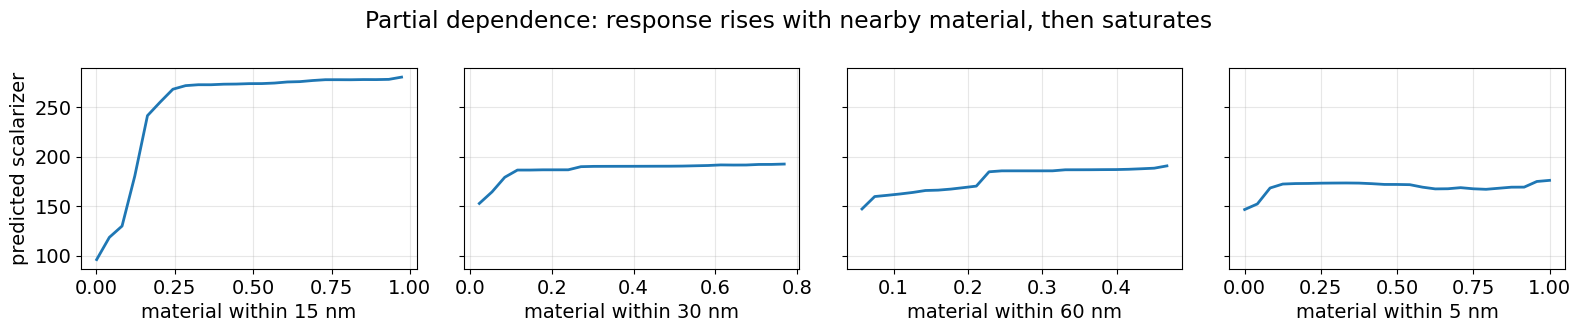

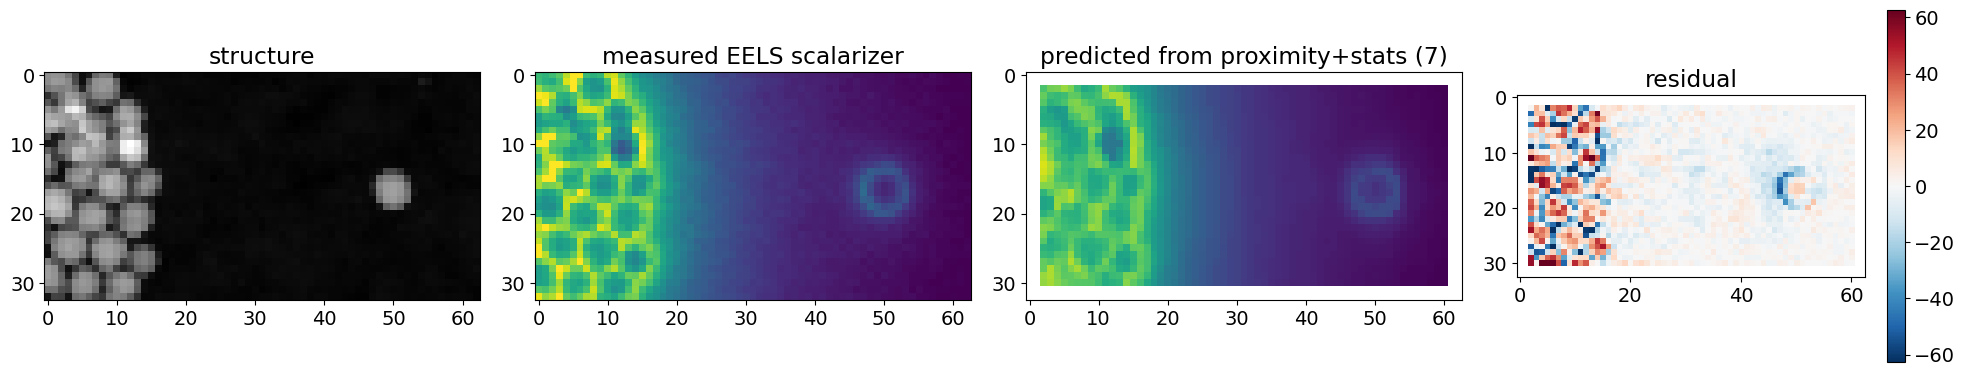

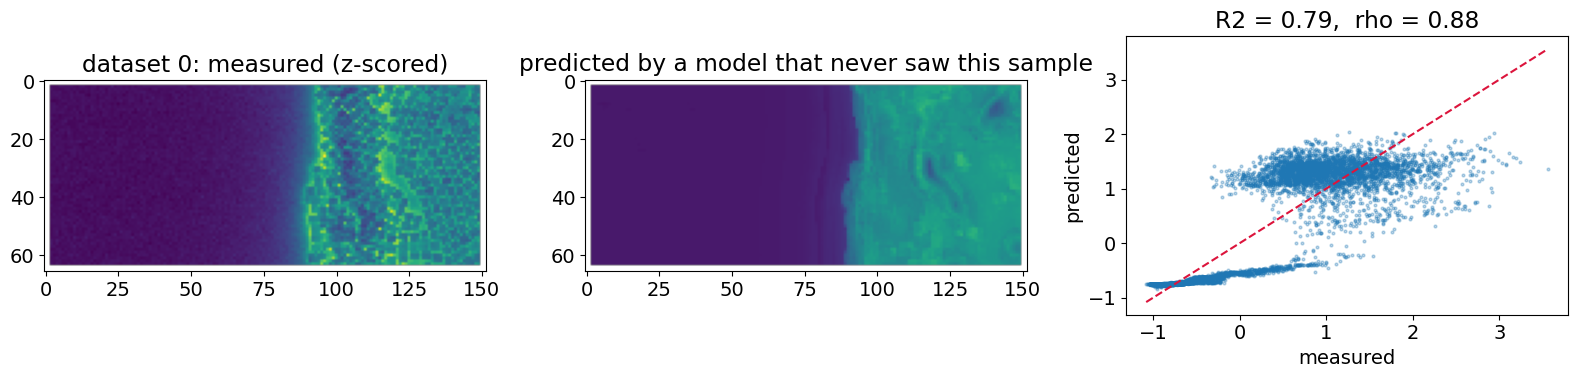


BEST MODEL
  descriptor : proximity+stats (7)  -> the particle mask convolved with Gaussians of
               sigma = 5, 15, 30, 60 nm, sampled at the point
  regressor  : HistGBM
  features   : 7
  test R2    : 0.99 (spatial split)
  transfer   : rho = 0.89 on samples never seen in training

WHAT DOES THE DESCRIPTOR MEASURE?
  Four numbers answering one question at four length scales:
  "how much material lies within r nanometres of this point?"
  It is not a texture and not a brightness -- it is a neighbourhood mass,
  measured in nanometres so it means the same thing at both magnifications
  in this file (5.1, 5.1, 2.6, 2.6 nm/px).

WHICH STRUCTURAL FEATURES ARE IMPORTANT?
  Permutation importance ranks them: material within 15 nm (0.56) > material within 30 nm (0.41) > material within 60 nm (0.33),
  and last patch mean at 0.000 -- essentially nothing.
  The best single radius on its own is 30 nm, so the response is set by
  material on a few tens of nanometres, not by what sits 

In [ ]:
# ============================================================
# YOUR CODE STARTS HERE
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score
from scipy.stats import spearmanr

# ------------------------------------------------------------------
# 1. PICK THE WINNER
#    Ranking rule: transfer to an unseen sample first (mean LODO rho),
#    then simplicity. Within-sample R2 is reported but NOT used to rank,
#    because cell 26 showed the position control scores 0.95 on it.
# ------------------------------------------------------------------
lodo_names, lodo_rho = results["lodo_names"], results["lodo_rho"]
desc, regs, S = results["desc"], results["reg"], results["scores"]
nfeat = results["n_features"]

mean_rho = lodo_rho.mean(axis=1)
ranked = sorted(range(len(lodo_names)), key=lambda i: (-mean_rho[i], nfeat[lodo_names[i]]))

print("ranked by transfer to an unseen sample")
print(f"{'descriptor':<22}{'#feat':>6}{'mean rho':>10}{'worst fold':>12}{'best R2 (spatial)':>19}")
for i in ranked:
    d = lodo_names[i]
    r2sp = np.nanmax(S["spatial blocks"][desc.index(d)])
    print(f"{d:<22}{nfeat[d]:6d}{mean_rho[i]:10.2f}{lodo_rho[i].min():12.2f}{r2sp:19.2f}")

BEST_D = lodo_names[ranked[0]]
row = desc.index(BEST_D)
BEST_R = regs[int(np.nanargmax(S["spatial blocks"][row]))]
print(f"\nBEST DESCRIPTOR : {BEST_D}")
print(f"BEST REGRESSOR  : {BEST_R}")
print(f"FEATURES        : {nfeat[BEST_D]}")
print(f"TEST R2         : {np.nanmax(S['spatial blocks'][row]):.3f} (spatial split, this dataset)")
print(f"                  {np.nanmax(S['random (leaky)'][row]):.3f} (random split -- inflated)")
print(f"TRANSFER        : rho = {mean_rho[ranked[0]]:.2f} "
      f"({', '.join('%.2f' % v for v in lodo_rho[ranked[0]])} on the four held-out samples)")

X = X_ALL[BEST_D]

# readable name for every column of the winning descriptor
if BEST_D.startswith("proximity"):
    FEATNAMES = [f"material within {r} nm" for r in PROX_NM]
    if "stats" in BEST_D:
        FEATNAMES += ["patch mean", "patch std", "patch range"]
elif BEST_D == "multiscale (10)":
    FEATNAMES = [f"{s} ({w}px)" for w in (3, 5, 11, 21, 41) for s in ("mean", "std")]
elif BEST_D == "geometry (4)":
    FEATNAMES = ["signed distance to edge", "|distance to edge|", "edge strength", "inside particle"]
else:
    FEATNAMES = [f"{BEST_D} f{i}" for i in range(X.shape[1])]
FEATNAMES = (FEATNAMES + [f"f{i}" for i in range(X.shape[1])])[:X.shape[1]]
N_PROX = sum(n.startswith("material within") for n in FEATNAMES)   # proximity columns, if any
best_model = RandomForestRegressor(300, min_samples_leaf=5, n_jobs=-1, random_state=0)
best_model.fit(X[spatial_train], targets[spatial_train])
print(f"\nrefit check: R2 = {r2_score(targets[spatial_test], best_model.predict(X[spatial_test])):.3f}")

# ------------------------------------------------------------------
# 2. WHICH FEATURES MATTER  (permutation importance, measured on held-out rows)
# ------------------------------------------------------------------
pi = permutation_importance(best_model, X[spatial_test], targets[spatial_test],
                            n_repeats=20, random_state=0, n_jobs=-1)
_ord = np.argsort(-pi.importances_mean)
print("\npermutation importance (drop in R2 when the feature is shuffled)")
for k in _ord:
    print(f"  {FEATNAMES[k]:<26} {pi.importances_mean[k]:6.3f} +- {pi.importances_std[k]:.3f}")

# each radius on its own -> which length scale carries the signal?
print("\nsingle-radius models (RandomForest, spatial split)")
solo = []
for k, r in enumerate(PROX_NM[:N_PROX]):
    mk = RandomForestRegressor(200, min_samples_leaf=5, n_jobs=-1, random_state=0)
    mk.fit(X[spatial_train, k:k+1], targets[spatial_train])
    s = r2_score(targets[spatial_test], mk.predict(X[spatial_test, k:k+1]))
    solo.append(s); print(f"  sigma = {r:2d} nm alone -> R2 = {s:.3f}")
print(f"  -> characteristic length of the response: ~{PROX_NM[int(np.argmax(solo))]} nm")

# a fully transparent linear version of the same descriptor
lin = make_pipeline(StandardScaler(), Ridge(1.0)).fit(X[spatial_train], targets[spatial_train])
co = lin[-1].coef_
print(f"\nlinear surrogate  R2 = {r2_score(targets[spatial_test], lin.predict(X[spatial_test])):.3f}")
print("  S ~ " + "  ".join(f"{c:+.0f}*[{n}]" for c, n in zip(co, FEATNAMES))
      + f"  {lin[-1].intercept_:+.0f}")

# ------------------------------------------------------------------
# 3. HOW THE PREDICTION DEPENDS ON EACH FEATURE  (partial dependence)
# ------------------------------------------------------------------
_top = _ord[:min(4, X.shape[1])]
fig, axes = plt.subplots(1, len(_top), figsize=(4*len(_top), 3.4), sharey=True, squeeze=False)
axes = axes[0]
sub = np.random.default_rng(0).choice(len(X), min(400, len(X)), replace=False)
for k, ax in zip(_top, axes):
    grid = np.linspace(np.percentile(X[:, k], 2), np.percentile(X[:, k], 98), 25)
    pd_ = []
    for v in grid:
        Xt = X[sub].copy(); Xt[:, k] = v
        pd_.append(best_model.predict(Xt).mean())
    ax.plot(grid, pd_, lw=2)
    ax.set_xlabel(FEATNAMES[k]); ax.grid(alpha=.3)
axes[0].set_ylabel("predicted scalarizer")
fig.suptitle("Partial dependence: response rises with nearby material, then saturates")
plt.tight_layout(); plt.show()

# ------------------------------------------------------------------
# 4. MAPS  (a)  within this dataset   (b)  a completely unseen sample
# ------------------------------------------------------------------
pred_map = np.full((H, W), np.nan)
pred_map[half:H-half, half:W-half] = best_model.predict(X).reshape(H-2*half, W-2*half)

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
ax[0].imshow(image, cmap="gray"); ax[0].set_title("structure")
v0, v1 = np.nanpercentile(scalarizer_map, [1, 99])
ax[1].imshow(scalarizer_map, vmin=v0, vmax=v1); ax[1].set_title("measured EELS scalarizer")
ax[2].imshow(pred_map, vmin=v0, vmax=v1); ax[2].set_title(f"predicted from {BEST_D}")
res = pred_map - scalarizer_map
m = np.nanpercentile(np.abs(res), 99)
h = ax[3].imshow(res, cmap="RdBu_r", vmin=-m, vmax=m); ax[3].set_title("residual")
plt.colorbar(h, ax=ax[3]); plt.tight_layout(); plt.show()

# held-out sample: train on every OTHER dataset, predict this one cold
hold = max(DS, key=lambda k: len(DS[k]["y"]))
tr_k = [k for k in DS if k != hold]
Xtr = np.vstack([zs(DS[k]["F"][BEST_D]) for k in tr_k])
ytr = np.concatenate([zs(DS[k]["y"]) for k in tr_k])
sub = np.random.default_rng(0).permutation(len(ytr))[:6000]
cold = RandomForestRegressor(300, min_samples_leaf=5, n_jobs=-1, random_state=0).fit(Xtr[sub], ytr[sub])
pc = cold.predict(zs(DS[hold]["F"][BEST_D])); yc = zs(DS[hold]["y"])
sh = tuple(DS[hold]["shape"]); yh, xh = DS[hold]["ys"], DS[hold]["xs"]
gt_m = np.full(sh, np.nan); pr_m = np.full(sh, np.nan)
gt_m[yh, xh] = yc; pr_m[yh, xh] = pc

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].imshow(gt_m); ax[0].set_title(f"dataset {hold}: measured (z-scored)")
ax[1].imshow(pr_m, vmin=np.nanmin(gt_m), vmax=np.nanmax(gt_m))
ax[1].set_title("predicted by a model that never saw this sample")
ax[2].scatter(yc, pc, s=4, alpha=.3)
lo, hi = min(yc.min(), pc.min()), max(yc.max(), pc.max())
ax[2].plot([lo, hi], [lo, hi], "--", color="crimson")
ax[2].set_xlabel("measured"); ax[2].set_ylabel("predicted")
ax[2].set_title(f"R2 = {r2_score(yc, pc):.2f},  rho = {spearmanr(yc, pc).statistic:.2f}")
plt.tight_layout(); plt.show()

# ------------------------------------------------------------------
# 5. THE ANSWERS
# ------------------------------------------------------------------
print(f"""
================================================================
BEST MODEL
  descriptor : {BEST_D}  -> the particle mask convolved with Gaussians of
               sigma = {', '.join(str(r) for r in PROX_NM)} nm, sampled at the point
  regressor  : {BEST_R}
  features   : {nfeat[BEST_D]}
  test R2    : {np.nanmax(S['spatial blocks'][row]):.2f} (spatial split)
  transfer   : rho = {mean_rho[ranked[0]]:.2f} on samples never seen in training

WHAT DOES THE DESCRIPTOR MEASURE?
  Four numbers answering one question at four length scales:
  "how much material lies within r nanometres of this point?"
  It is not a texture and not a brightness -- it is a neighbourhood mass,
  measured in nanometres so it means the same thing at both magnifications
  in this file ({', '.join('%.1f' % float(np.asarray(loadedfile[k]['scale'])) for k in loadedfile)} nm/px).

WHICH STRUCTURAL FEATURES ARE IMPORTANT?
  Permutation importance ranks them: {' > '.join(f'{FEATNAMES[k]} ({pi.importances_mean[k]:.2f})' for k in _ord[:3])},
  and last {FEATNAMES[_ord[-1]]} at {pi.importances_mean[_ord[-1]]:.3f} -- essentially nothing.
  The best single radius on its own is {PROX_NM[int(np.argmax(solo))]} nm, so the response is set by
  material on a few tens of nanometres, not by what sits directly under the beam.
  Local texture inside the 5x5 window is nearly irrelevant: cell 26 showed
  all 25 raw pixels (rho = {lodo_rho[lodo_names.index('raw 5x5 (25)')].mean():.2f}) do no better than 3 summary
  statistics (rho = {lodo_rho[lodo_names.index('stats3 (3)')].mean():.2f}).

WHY SHOULD THIS BE RELATED TO THE EELS RESPONSE?
  At 0.5-1.0 eV the loss is a surface plasmon, not a core excitation. The
  fast electron couples to it through its evanescent field, which reaches
  out over an impact parameter of tens of nanometres. The measured maps
  show this directly: a bright halo extends well into the vacuum around
  every assembly, so there is a strong signal where there is no material
  at all. A quantity that integrates nearby material over that same length
  scale is therefore the natural descriptor -- and a 5x5 patch
  ({PATCH_SIZE * float(np.asarray(data['scale'])):.0f} nm across) is simply the wrong size of window to see it.
  The partial-dependence curves rise and then saturate, which is what an
  excitation probability bounded above should look like.
================================================================""")
# ============================================================
# YOUR CODE ENDS HERE
# ============================================================


### Final question

> Which descriptor–regressor combination gives the best predictive performance while remaining simple and explainable?